# Notebook 05 — Estadística Práctica, Gráficos Industriales y Primer Modelo ML
**Pungo Academy · Python y Ciencia de Datos Industrial desde Cero en Google Colab**

## Objetivo
Transformar datos limpios en **criterio estadístico, gráficos de ingeniería y tu primer modelo predictivo**:
1. Comparar **Media vs. Mediana**, Desviación Estándar, **IQR** y Percentiles (`P5`, `P95`) sobre `CCPP` (`9,568 × 5`).
2. Construir gráficos ejecutivos con límites operativos claros (histogramas, boxplots, matriz de correlación y dispersión).
3. Entender la diferencia entre **Correlación** y **Causalidad Física** en turbinas de gas.
4. Cruzar el **Puente hacia Machine Learning** con una **Regresión Lineal en 6 líneas** (`X`, `y`, `train_test_split`, `MAE` y `R²`).

In [1]:
# 1. Estadística descriptiva práctica y robusta sobre CCPP (9,568 horas de operación)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Paleta corporativa oficial Pungo Tech 2027
PUNGO_NAVY = "#0D202B"
PUNGO_BLUE = "#007297"
PUNGO_LIME = "#8EC14B"
PUNGO_AMBER = "#E8820C"
PUNGO_RED = "#C0392B"
PUNGO_SLATE = "#475569"
plt.rcParams["figure.figsize"] = (11.5, 5.5)
plt.rcParams["figure.dpi"] = 150
plt.rcParams["font.size"] = 11
plt.rcParams["axes.edgecolor"] = "#CBD5E1"
plt.rcParams["axes.titleweight"] = "bold"
plt.style.use("seaborn-v0_8-whitegrid")

df_ccpp = pd.read_csv("https://d29ikw7e1z6k4e.cloudfront.net/curso_python_cero/curso_python_cero_ccpp.csv")
df_planta = pd.read_csv("https://d29ikw7e1z6k4e.cloudfront.net/curso_python_cero/curso_python_cero_planta_turnos.csv").drop_duplicates()

pe = df_ccpp["PE"]
q25, q50, q75 = pe.quantile([0.25, 0.50, 0.75])
iqr = q75 - q25
p5, p95 = np.percentile(pe, [5, 95])

print("=== ESTADÍSTICAS DE GENERACIÓN ELÉCTRICA (PE en MW) ===")
print(f"Media      : {pe.mean():.2f} MW | Mediana (P50): {q50:.2f} MW")
print(f"Desv. Est. : {pe.std():.2f} MW | IQR (Q3-Q1)  : {iqr:.2f} MW")
print(f"Rango P5–P95: {p5:.2f} a {p95:.2f} MW (90% de las horas operativas)")

=== ESTADÍSTICAS DE GENERACIÓN ELÉCTRICA (PE en MW) ===
Media      : 454.37 MW | Mediana (P50): 451.55 MW
Desv. Est. : 17.07 MW | IQR (Q3-Q1)  : 28.68 MW
Rango P5–P95: 430.80 a 483.52 MW (90% de las horas operativas)


## Paso 2 — Visualizaciones Industriales con Contexto Operativo
Un gráfico industrial nunca se entrega desnudo: siempre incluye **unidades físicas**, **umbrales operativos** y **título que explica el hallazgo**.

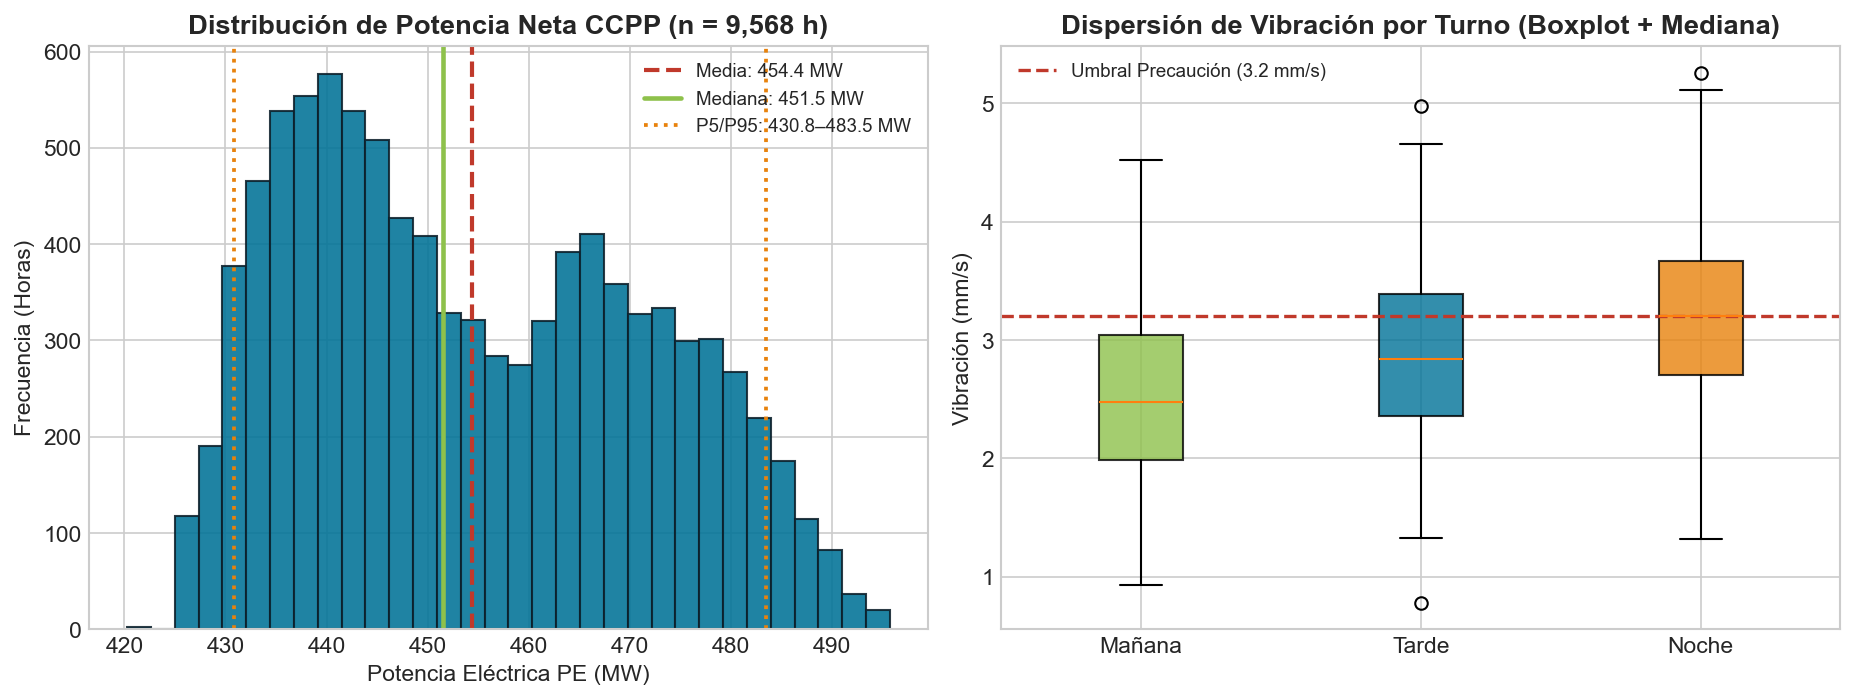

In [2]:
# 2. Panel de distribución de generación CCPP y variabilidad por turno en planta
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))

# Panel A: Distribución de PE (MW) con Media, Mediana y banda P5-P95
axes[0].hist(pe, bins=32, color=PUNGO_BLUE, edgecolor=PUNGO_NAVY, alpha=0.88)
axes[0].axvline(pe.mean(), color=PUNGO_RED, linestyle="--", linewidth=2, label=f"Media: {pe.mean():.1f} MW")
axes[0].axvline(q50, color=PUNGO_LIME, linestyle="-", linewidth=2.2, label=f"Mediana: {q50:.1f} MW")
axes[0].axvline(p5, color=PUNGO_AMBER, linestyle=":", linewidth=1.8, label=f"P5/P95: {p5:.1f}–{p95:.1f} MW")
axes[0].axvline(p95, color=PUNGO_AMBER, linestyle=":", linewidth=1.8)
axes[0].set_title("Distribución de Potencia Neta CCPP (n = 9,568 h)")
axes[0].set_xlabel("Potencia Eléctrica PE (MW)")
axes[0].set_ylabel("Frecuencia (Horas)")
axes[0].legend(fontsize=9)

# Panel B: Boxplot de vibración por turno con límite de precaución
orden_turnos = ["Manana", "Tarde", "Noche"]
datos_box = [df_planta[df_planta["turno"] == t]["vibracion_mms"].values for t in orden_turnos]
bp = axes[1].boxplot(datos_box, tick_labels=["Mañana", "Tarde", "Noche"], patch_artist=True)
for patch, c in zip(bp["boxes"], [PUNGO_LIME, PUNGO_BLUE, PUNGO_AMBER]):
    patch.set_facecolor(c)
    patch.set_alpha(0.8)
axes[1].axhline(3.2, color=PUNGO_RED, linestyle="--", linewidth=1.6, label="Umbral Precaución (3.2 mm/s)")
axes[1].set_title("Dispersión de Vibración por Turno (Boxplot + Mediana)")
axes[1].set_ylabel("Vibración (mm/s)")
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

## Paso 3 — Matriz de Correlación y Física de Turbina (`AT` vs. `PE`)
En una turbina de gas de ciclo combinado, cuando aumenta la **temperatura ambiente (`AT`)**, baja la densidad del aire que entra al compresor y disminuye la potencia neta (`PE`). Vamos a comprobarlo cuantitativamente.

=== MATRIZ DE CORRELACIÓN CCPP ===
       AT      V     AP     RH     PE
AT  1.000  0.844 -0.508 -0.543 -0.948
V   0.844  1.000 -0.414 -0.312 -0.870
AP -0.508 -0.414  1.000  0.100  0.518
RH -0.543 -0.312  0.100  1.000  0.390
PE -0.948 -0.870  0.518  0.390  1.000


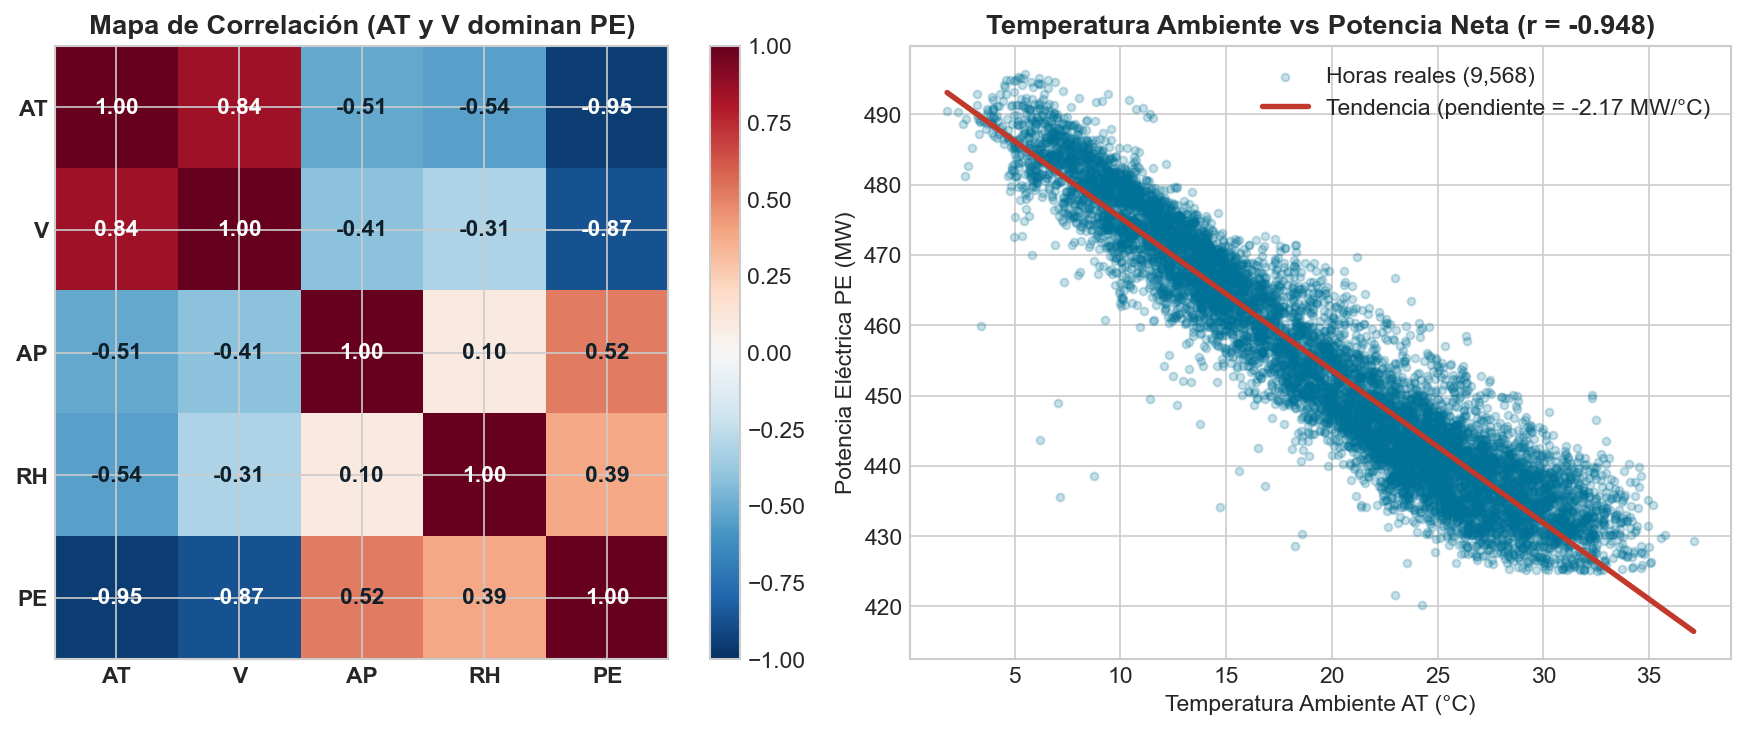

In [3]:
# 3. Correlaciones de Pearson y gráfico de dispersión AT vs PE
corr = df_ccpp.corr(numeric_only=True).round(3)
print("=== MATRIZ DE CORRELACIÓN CCPP ===")
print(corr)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.0))

# Heatmap manual limpio con valores impresos
im = axes[0].imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(corr.columns)))
axes[0].set_yticks(range(len(corr.columns)))
axes[0].set_xticklabels(corr.columns, fontweight="bold")
axes[0].set_yticklabels(corr.columns, fontweight="bold")
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        val = corr.values[i, j]
        txt_col = "white" if abs(val) > 0.55 else PUNGO_NAVY
        axes[0].text(j, i, f"{val:.2f}", ha="center", va="center", color=txt_col, fontweight="bold")
axes[0].set_title("Mapa de Correlación (AT y V dominan PE)")
fig.colorbar(im, ax=axes[0], fraction=0.046)

# Scatter plot AT vs PE con línea de tendencia
axes[1].scatter(df_ccpp["AT"], df_ccpp["PE"], alpha=0.22, s=14, color=PUNGO_BLUE, label="Horas reales (9,568)")
m, b = np.polyfit(df_ccpp["AT"], df_ccpp["PE"], 1)
x_line = np.linspace(df_ccpp["AT"].min(), df_ccpp["AT"].max(), 100)
axes[1].plot(x_line, m * x_line + b, color=PUNGO_RED, linewidth=2.6, label=f"Tendencia (pendiente = {m:.2f} MW/°C)")
axes[1].set_title(f"Temperatura Ambiente vs Potencia Neta (r = {corr.loc['AT', 'PE']:.3f})")
axes[1].set_xlabel("Temperatura Ambiente AT (°C)")
axes[1].set_ylabel("Potencia Eléctrica PE (MW)")
axes[1].legend()

plt.tight_layout()
plt.show()

## Paso 4 — Puente Suave al Machine Learning (Tu Primer Modelo en 6 Líneas)
La estadística describe el pasado; **Machine Learning** usa esas variables de entrada (`X`: `AT, V, AP, RH`) para predecir la variable objetivo (`y`: `PE`) en condiciones futuras nunca vistas.
Para evitar memorización tramposa, siempre dividimos en **80% Entrenamiento** (*cuaderno de estudio*) y **20% Prueba** (*examen final*).

In [4]:
# 4. Primer modelo de Machine Learning supervisado: Regresión Lineal sobre CCPP
X = df_ccpp[["AT", "V", "AP", "RH"]]
y = df_ccpp["PE"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

modelo = LinearRegression()
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = float(np.sqrt(mean_squared_error(y_test, y_pred)))
r2 = r2_score(y_test, y_pred)

print(f"Muestras -> Entrenamiento: {len(X_train):,} (80%) | Prueba: {len(X_test):,} (20%)")
print(f"MAE (Error Absoluto Medio): {mae:.2f} MW (sobre ~454 MW promedio)")
print(f"RMSE: {rmse:.2f} MW | R²: {r2:.4f} ({r2*100:.1f}% de varianza explicada)")

print("\nPesos físicos aprendidos por el modelo:")
for col, coef in zip(X.columns, modelo.coef_):
    print(f"  {col:3s} -> {coef:+.4f} MW por unidad")

Muestras -> Entrenamiento: 7,654 (80%) | Prueba: 1,914 (20%)
MAE (Error Absoluto Medio): 3.60 MW (sobre ~454 MW promedio)
RMSE: 4.50 MW | R²: 0.9301 (93.0% de varianza explicada)

Pesos físicos aprendidos por el modelo:
  AT  -> -1.9859 MW por unidad
  V   -> -0.2321 MW por unidad
  AP  -> +0.0622 MW por unidad
  RH  -> -0.1581 MW por unidad


## Paso 5 — Diagnóstico Visual del Modelo y Simulación de Planta Nueva
Comparamos los valores reales contra los predichos en el conjunto de prueba y simulamos un nuevo punto de operación ambiental.

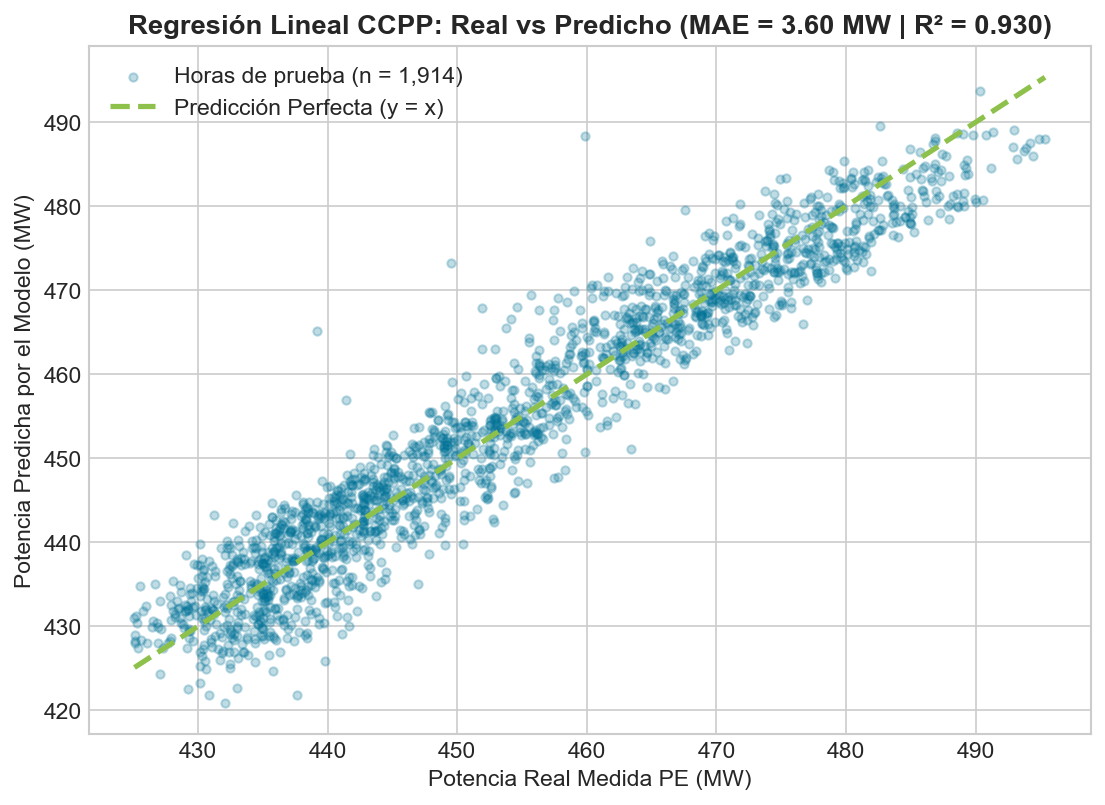

Simulación día caluroso (AT=28°C, V=62, AP=1011, RH=78%) -> Potencia estimada: 435.13 MW


In [5]:
# 5. Gráfico Real vs Predicho en test + Simulación operativa en vivo
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.scatter(y_test, y_pred, alpha=0.25, s=16, color=PUNGO_BLUE, label="Horas de prueba (n = 1,914)")
lims = [y_test.min(), y_test.max()]
ax.plot(lims, lims, color=PUNGO_LIME, linewidth=2.5, linestyle="--", label="Predicción Perfecta (y = x)")
ax.set_title(f"Regresión Lineal CCPP: Real vs Predicho (MAE = {mae:.2f} MW | R² = {r2:.3f})")
ax.set_xlabel("Potencia Real Medida PE (MW)")
ax.set_ylabel("Potencia Predicha por el Modelo (MW)")
ax.legend()
plt.tight_layout()
plt.show()

# Simulación de nuevo escenario operativo
nuevo_dia = pd.DataFrame([{"AT": 28.0, "V": 62.0, "AP": 1011.0, "RH": 78.0}])
pe_estimada = float(modelo.predict(nuevo_dia)[0])
print(f"Simulación día caluroso (AT=28°C, V=62, AP=1011, RH=78%) -> Potencia estimada: {pe_estimada:.2f} MW")

## Paso 6 — Tu Turno (Ejercicios Módulo 5)
1. **Reto 5.1:** Usa el `modelo` ya entrenado para comparar la potencia predicha en una mañana fresca (`AT=12.0, V=42.0, AP=1018.0, RH=70.0`) frente a una tarde calurosa (`AT=32.0, V=68.0, AP=1008.0, RH=60.0`). ¿Cuántos MW de capacidad cambia la planta?

In [6]:
# Solución verificada — Tu Turno Módulo 5
escenarios = pd.DataFrame([
    {"AT": 12.0, "V": 42.0, "AP": 1018.0, "RH": 70.0},
    {"AT": 32.0, "V": 68.0, "AP": 1008.0, "RH": 60.0},
])
preds = modelo.predict(escenarios)
print(f"Mañana fresca (12°C): {preds[0]:.2f} MW")
print(f"Tarde calurosa (32°C): {preds[1]:.2f} MW")
print(f"Diferencia predicha de capacidad: {preds[0] - preds[1]:.2f} MW")

Mañana fresca (12°C): 473.24 MW
Tarde calurosa (32°C): 428.45 MW
Diferencia predicha de capacidad: 44.79 MW
